# STATE Kimi R2 — Fixed-reference and embedding checks

Run the six sections in order. The three axes share one model-prediction stage. Validated predictions can be reused; all metadata axes, score calculations, references, controls and plots are recalculated in the cells. No released-score substitution is used.

Use Python 3.11, torch 2.7.1, transformers 4.52.4, anndata 0.12.19, numpy 2.4.2, pandas 2.3.3, scipy 1.17.1, scikit-learn 1.6.1, scanpy 1.11.2, h5py 3.14.0, cell-load 0.10.4, cell-eval 0.8.1, pdex 0.2.5, peft 0.15.2, numba 0.64.0 and matplotlib 3.10.8. Install public STATE with `python -m pip install git+https://github.com/ArcInstitute/state.git@da4178c930dc917dac6b56faf10a33e21bd8e905`.

`STATE_KIMI2_INPUTS` selects the shared raw/prediction cache. Set `STATE_GPU` to an idle GPU index for missing predictions; otherwise the model runs on CPU. The raw dataset is 30.01 GB; prediction and prepared-input files require additional space.

## 1. Data source and acquisition

The filtered Replogle dataset and four ST-SE zero-shot checkpoints are pinned by content hash.

In [1]:
from pathlib import Path
from typing import Dict,List,Optional
import os,json,hashlib,time,platform,urllib.request,shutil,argparse,subprocess,collections,pickle
os.environ['OMP_NUM_THREADS']='2';os.environ['OPENBLAS_NUM_THREADS']='2';os.environ['MKL_NUM_THREADS']='2'
GPU=os.environ.get('STATE_GPU','')
os.environ['CUDA_VISIBLE_DEVICES']=GPU
import numpy as np
import pandas as pd
import anndata as ad
import torch
from scipy import stats
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display
RAW=Path(os.environ.get('STATE_KIMI2_INPUTS','state_kimi2_inputs')).resolve();RAW.mkdir(parents=True,exist_ok=True)
WORK=Path('test-03_outputs').resolve();(WORK/'data').mkdir(parents=True,exist_ok=True);(WORK/'results').mkdir(parents=True,exist_ok=True)
START=time.time()
def sha(p):
    h=hashlib.sha256()
    with open(p,'rb') as f:
        for b in iter(lambda:f.read(16777216),b''):h.update(b)
    return h.hexdigest()
def verified(p,item):return p.is_file() and p.stat().st_size==item['bytes'] and sha(p)==item['sha256']
def fetch(item):
    p=RAW/item['path']
    if verified(p,item):return
    p.parent.mkdir(parents=True,exist_ok=True);tmp=p.with_suffix(p.suffix+'.part')
    with urllib.request.urlopen(urllib.request.Request(item['url'],headers={'User-Agent':'STATE-notebook/1.0'}),timeout=300) as source,tmp.open('wb') as target:
        shutil.copyfileobj(source,target,16777216)
    if not verified(tmp,item):raise ValueError('Input identity mismatch: '+item['path'])
    tmp.replace(p)

from io import BytesIO
from IPython.display import Image
def display_figure(figure):
    buffer=BytesIO()
    figure.savefig(buffer,format='png',dpi=140,bbox_inches='tight')
    display(Image(data=buffer.getvalue()))


In [2]:
SOURCES = [{'path': 'models/zeroshot_hepg2/batch_onehot_map.pkl',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c/zeroshot/hepg2/batch_onehot_map.pkl',
  'bytes': 721431,
  'sha256': '19d2d7934bbbc7413f4d2d3d164bbbd0a868464c3c04cebcc1113990e7136f99'},
 {'path': 'models/zeroshot_hepg2/cell_type_onehot_map.pkl',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c/zeroshot/hepg2/cell_type_onehot_map.pkl',
  'bytes': 1799,
  'sha256': '18d2aa8ddc6c74bd818f8f318d7c7dd31032852a35ebae5f207f07c8e8418113'},
 {'path': 'models/zeroshot_hepg2/checkpoints/best.ckpt',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c/zeroshot/hepg2/checkpoints/best.ckpt',
  'bytes': 510117003,
  'sha256': 'c6f4903cd44be6c10161befc3ade42fd63596552c5f7d7378736830446bb9d5b'},
 {'path': 'models/zeroshot_hepg2/config.yaml',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c/zeroshot/hepg2/config.yaml',
  'bytes': 2768,
  'sha256': '5f9f1f487253ee9d3df20a6dc106c9263873adb7f262c6625f1f11cbd45e5520'},
 {'path': 'models/zeroshot_hepg2/pert_onehot_map.pt',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c/zeroshot/hepg2/pert_onehot_map.pt',
  'bytes': 16746593,
  'sha256': 'f5621cab243a5135014af3867f63f8bf75cff19aee06d0f29a1bdecd2dbf47d0'},
 {'path': 'models/zeroshot_hepg2/var_dims.pkl',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c/zeroshot/hepg2/var_dims.pkl',
  'bytes': 155642,
  'sha256': 'f7446d88ec457cf174b0bb97384c49b7b0f8254a94b7aaf61c0275289cbf63f9'},
 {'path': 'models/zeroshot_jurkat/batch_onehot_map.pkl',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c/zeroshot/jurkat/batch_onehot_map.pkl',
  'bytes': 721431,
  'sha256': 'b56fb381196fe8d90709dec2cd5d24644fb940f76852df884462cccfde243ba3'},
 {'path': 'models/zeroshot_jurkat/cell_type_onehot_map.pkl',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c/zeroshot/jurkat/cell_type_onehot_map.pkl',
  'bytes': 1799,
  'sha256': 'e9215091660f466a30722238a894c675ac08f592f4c847b5aba8373bc8851340'},
 {'path': 'models/zeroshot_jurkat/checkpoints/best.ckpt',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c/zeroshot/jurkat/checkpoints/best.ckpt',
  'bytes': 510117003,
  'sha256': '66a50d54a1c3d31744ed067814afcfdf2b3a2ee0645c1dd555134f0e9cdd4f65'},
 {'path': 'models/zeroshot_jurkat/config.yaml',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c/zeroshot/jurkat/config.yaml',
  'bytes': 2770,
  'sha256': '603dc32b0ab330c818abf6382adece3ca5f87bee7f2e984d5273baf11b5e9a74'},
 {'path': 'models/zeroshot_jurkat/pert_onehot_map.pt',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c/zeroshot/jurkat/pert_onehot_map.pt',
  'bytes': 16746593,
  'sha256': 'f5621cab243a5135014af3867f63f8bf75cff19aee06d0f29a1bdecd2dbf47d0'},
 {'path': 'models/zeroshot_jurkat/var_dims.pkl',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c/zeroshot/jurkat/var_dims.pkl',
  'bytes': 155642,
  'sha256': 'f7446d88ec457cf174b0bb97384c49b7b0f8254a94b7aaf61c0275289cbf63f9'},
 {'path': 'models/zeroshot_k562/batch_onehot_map.pkl',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c/zeroshot/k562/batch_onehot_map.pkl',
  'bytes': 721431,
  'sha256': '502b6bb6f923004af05bd89e5d6ee6ae60b30b15c0f1f3d68b054a0da2447338'},
 {'path': 'models/zeroshot_k562/cell_type_onehot_map.pkl',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c/zeroshot/k562/cell_type_onehot_map.pkl',
  'bytes': 1799,
  'sha256': 'a2b13b74692acac5c7c0bdc5f6b8cfa5bb964d56eedac76a100430d1340fc93e'},
 {'path': 'models/zeroshot_k562/checkpoints/best.ckpt',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c/zeroshot/k562/checkpoints/best.ckpt',
  'bytes': 510117003,
  'sha256': 'dcf0247da478aaf5b470a429fa04c44546b58a5d4a0a45d6262d6662b499b061'},
 {'path': 'models/zeroshot_k562/config.yaml',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c/zeroshot/k562/config.yaml',
  'bytes': 2766,
  'sha256': '9a581a5ee3de002d859f62c2119d0e7ee3c4ceb6bdf1d370270c0fc11bb4ea67'},
 {'path': 'models/zeroshot_k562/pert_onehot_map.pt',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c/zeroshot/k562/pert_onehot_map.pt',
  'bytes': 16746593,
  'sha256': 'f5621cab243a5135014af3867f63f8bf75cff19aee06d0f29a1bdecd2dbf47d0'},
 {'path': 'models/zeroshot_k562/var_dims.pkl',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c/zeroshot/k562/var_dims.pkl',
  'bytes': 155642,
  'sha256': 'f7446d88ec457cf174b0bb97384c49b7b0f8254a94b7aaf61c0275289cbf63f9'},
 {'path': 'models/zeroshot_rpe1/batch_onehot_map.pkl',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c/zeroshot/rpe1/batch_onehot_map.pkl',
  'bytes': 721431,
  'sha256': '073efdd482278bcfd6604727a8087e91fa9196bf6ee32292f8ab60816c1013b7'},
 {'path': 'models/zeroshot_rpe1/cell_type_onehot_map.pkl',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c/zeroshot/rpe1/cell_type_onehot_map.pkl',
  'bytes': 1799,
  'sha256': '2056b1eb85b155f25bf292d2020c2e3f40c77e548090b63944c3521b17b6a1f8'},
 {'path': 'models/zeroshot_rpe1/checkpoints/best.ckpt',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c/zeroshot/rpe1/checkpoints/best.ckpt',
  'bytes': 510117003,
  'sha256': 'e37ed65051ad911e2e52b230287698aa5a1f883e9c70695eac6e59b2e689cdf1'},
 {'path': 'models/zeroshot_rpe1/config.yaml',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c/zeroshot/rpe1/config.yaml',
  'bytes': 2766,
  'sha256': 'c498d404991c6c8c1f95b2224ab3d8e2a50952cfe964eaa5b9661311d80bd5d1'},
 {'path': 'models/zeroshot_rpe1/pert_onehot_map.pt',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c/zeroshot/rpe1/pert_onehot_map.pt',
  'bytes': 16746593,
  'sha256': 'f5621cab243a5135014af3867f63f8bf75cff19aee06d0f29a1bdecd2dbf47d0'},
 {'path': 'models/zeroshot_rpe1/var_dims.pkl',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c/zeroshot/rpe1/var_dims.pkl',
  'bytes': 155642,
  'sha256': 'f7446d88ec457cf174b0bb97384c49b7b0f8254a94b7aaf61c0275289cbf63f9'},
 {'path': 'data/splits/hepg2_zeroshot.toml',
  'url': 'https://huggingface.co/datasets/arcinstitute/State-Replogle-Filtered/resolve/d790193bb2c93726541a75ca3fa873a92ed44da5/hepg2_zeroshot.toml',
  'bytes': 429,
  'sha256': '2cc13dbc83b4afe44544eab8ee6277333eb020630d3e80644d514ec68bfceba0'},
 {'path': 'data/splits/jurkat_zeroshot.toml',
  'url': 'https://huggingface.co/datasets/arcinstitute/State-Replogle-Filtered/resolve/d790193bb2c93726541a75ca3fa873a92ed44da5/jurkat_zeroshot.toml',
  'bytes': 430,
  'sha256': '7ed319aac657bb54f403fc84770fcc4250cd7b99e5a12c84dbfcc6acdb06639c'},
 {'path': 'data/splits/k562_zeroshot.toml',
  'url': 'https://huggingface.co/datasets/arcinstitute/State-Replogle-Filtered/resolve/d790193bb2c93726541a75ca3fa873a92ed44da5/k562_zeroshot.toml',
  'bytes': 428,
  'sha256': '76590c2a12fff844f54aad994607d8c366151be5d8b503114cf76b8b9d3e006e'},
 {'path': 'data/replogle_concat.h5ad',
  'url': 'https://huggingface.co/datasets/arcinstitute/State-Replogle-Filtered/resolve/d790193bb2c93726541a75ca3fa873a92ed44da5/replogle_concat.h5ad',
  'bytes': 30010775846,
  'sha256': 'a7992a6109d589f2d49c2eaccff45a9f860418af23125d41b80d8e3929a33d56'},
 {'path': 'data/splits/rpe1_zeroshot.toml',
  'url': 'https://huggingface.co/datasets/arcinstitute/State-Replogle-Filtered/resolve/d790193bb2c93726541a75ca3fa873a92ed44da5/rpe1_zeroshot.toml',
  'bytes': 428,
  'sha256': 'a39a8ca7adcd3f5256546e3448ffcf8d829946f39189d1e65814581e55736467'}]
for item in SOURCES:fetch(item)
print("Verified public source files:",len(SOURCES))

Verified public source files: 29


## 2. Data processing

Preserve every source cell and its row order. The inference input contains X_state and X_hvg as float32, with a one-column zero placeholder X. No cell subsampling is applied.

In [3]:
source=ad.read_h5ad(RAW/'data/replogle_concat.h5ad',backed='r')
obs=source.obs[['gem_group','gene','cell_line','UMI_count','mitopercent']].copy()
for col in ['gem_group','gene','cell_line']:obs[col]=obs[col].astype(str)
obs.to_parquet(WORK/'data/obs_meta.parquet')
print('Cells:',len(obs));display(obs.cell_line.value_counts())
if source.shape[0]!=len(obs):raise ValueError('Observation/expression row mismatch')


Cells: 643413


cell_line
k562      188590
jurkat    184470
rpe1      173737
hepg2      96616
Name: count, dtype: int64

## 3. Axis definition and level construction

For each held-out context, training support is the number of cells carrying that gene perturbation in the other three contexts. Keep test perturbations with at least 30 cells. Levels are zero, 1–100, 101–250, and more than 250 supporting cells. Binary exposure distinguishes zero from any supporting training context.

In [4]:
support_rows=[]
for ctx in ['k562','jurkat','hepg2','rpe1']:
    train=obs[obs.cell_line.ne(ctx)];test=obs[obs.cell_line.eq(ctx)];counts=test.groupby('gene',observed=True).size();support=train.groupby('gene',observed=True).size()
    line_counts=train.groupby('gene',observed=True).cell_line.nunique()
    for gene,n in counts.items():
        if gene=='non-targeting' or n<30:continue
        support_rows.append({'context':ctx,'pert':gene,'n_test_cells':int(n),'support':int(support.get(gene,0)),'n_training_lines':int(line_counts.get(gene,0))})
axis_table=pd.DataFrame(support_rows);axis_table['level']=pd.cut(axis_table.support,[-1,0,100,250,10**9],labels=['L0','L1','L2','L3'])
k=axis_table[axis_table.context.eq('k562')].set_index('pert').support;k.to_csv(WORK/'data/training_support_k562_perts.csv')
display(axis_table.groupby(['context','level'],observed=True).agg(units=('pert','size'),median_support=('support','median')))


units  median_support
context level                       
hepg2   L0        62             0.0
        L1       139            69.0
        L2       473           185.0
        L3       666           358.0
jurkat  L0        71             0.0
        L1       237            72.0
        L2       729           174.0
        L3       500           328.5
k562    L0        74             0.0
        L1       260            69.0
        L2       678           168.0
        L3       371           337.0
rpe1    L0        66             0.0
        L1       205            66.0
        L2       670           174.5
        L3       558           335.5

## 4. Model evaluation and reference scores

The complete public inference procedure is below. It uses checkpoint cell-set length 64 and seed 42. Reuse requires the exact input, checkpoint, code identity and prediction hash. Observed deltas subtract observed controls; STATE deltas subtract predicted controls. R1 averages the same gene’s observed deltas across other contexts; missing same-gene references fall back to R2, the equally weighted mean of all training gene–context deltas.

In [5]:
PUBLIC_INFERENCE_SHA256 = 'dffe0684e93dbacbb1b6ad1c29325da215ba78a46eeb424e87b916990cd2262a'
INPUT_RECORDS = {'hepg2': {'bytes': 1574538376,
           'path': 'data/hepg2_infer_input.h5ad',
           'sha256': '4d7759366c92c9ec7515f6fb483311427159ee2af1191df1490e392e0b28fd48'},
 'jurkat': {'bytes': 3006242544,
            'path': 'data/jurkat_infer_input.h5ad',
            'sha256': '2ee731f2a175b1472a4b04bee1d729b30d52d042679e51177938fa27cbd7de1e'},
 'k562': {'bytes': 3073345128,
          'path': 'data/k562_infer_input.h5ad',
          'sha256': '4fbbf4058e34051ca5d471be76ba5a523d530aaeee41f2ca7323c4de8886ab42'},
 'rpe1': {'bytes': 2831310848,
          'path': 'data/rpe1_infer_input.h5ad',
          'sha256': 'c2bcb96194f9d36a025eda9193d596e48d263168c415048251287af9cb25e1cf'}}
SHARED_INFERENCE = {'hepg2': {'inputs': ['0b379678df372b048569b7ade6e0192363eb0cac9329784e0906243337df8db3',
                      'c6f4903cd44be6c10161befc3ade42fd63596552c5f7d7378736830446bb9d5b',
                      '4d7759366c92c9ec7515f6fb483311427159ee2af1191df1490e392e0b28fd48'],
           'outputs': [{'bytes': 1574538376,
                        'path': 'results/hepg2_pred_best.h5ad',
                        'sha256': '281d345f7986a24b27b2c6d5147fa37bef1c2a558eb2d96485fc6deddcb9e678'}],
           'policy': {'code_commit': 'da4178c930dc917dac6b56faf10a33e21bd8e905', 'inference_seed': 42}},
 'jurkat': {'inputs': ['0b379678df372b048569b7ade6e0192363eb0cac9329784e0906243337df8db3',
                       '66a50d54a1c3d31744ed067814afcfdf2b3a2ee0645c1dd555134f0e9cdd4f65',
                       '2ee731f2a175b1472a4b04bee1d729b30d52d042679e51177938fa27cbd7de1e'],
            'outputs': [{'bytes': 3006242544,
                         'path': 'results/jurkat_pred_best.h5ad',
                         'sha256': '5c91cf6b1b859e5ec9805f56e7fb53010e3b863ea083c143b589617acff13f85'}],
            'policy': {'code_commit': 'da4178c930dc917dac6b56faf10a33e21bd8e905', 'inference_seed': 42}},
 'k562': {'inputs': ['0b379678df372b048569b7ade6e0192363eb0cac9329784e0906243337df8db3',
                     'dcf0247da478aaf5b470a429fa04c44546b58a5d4a0a45d6262d6662b499b061',
                     '4fbbf4058e34051ca5d471be76ba5a523d530aaeee41f2ca7323c4de8886ab42'],
          'outputs': [{'bytes': 3073345128,
                       'path': 'results/k562_pred_best.h5ad',
                       'sha256': '9b8b1c1be5599a79ce068ccfdfb7b4f96fd43c2f917688b76336d315d9b4c64c'}],
          'policy': {'code_commit': 'da4178c930dc917dac6b56faf10a33e21bd8e905', 'inference_seed': 42}},
 'rpe1': {'inputs': ['0b379678df372b048569b7ade6e0192363eb0cac9329784e0906243337df8db3',
                     'e37ed65051ad911e2e52b230287698aa5a1f883e9c70695eac6e59b2e689cdf1',
                     'c2bcb96194f9d36a025eda9193d596e48d263168c415048251287af9cb25e1cf'],
          'outputs': [{'bytes': 2831310848,
                       'path': 'results/rpe1_pred_best.h5ad',
                       'sha256': '1de33ae6985f1ec0bcf98ae0296d3ee20ad5644506564994a1b5570c82aada2b'}],
          'policy': {'code_commit': 'da4178c930dc917dac6b56faf10a33e21bd8e905', 'inference_seed': 42}}}

In [6]:
import argparse
from typing import Dict, List, Optional
import pandas as pd


def add_arguments_infer(parser: argparse.ArgumentParser):
    parser.add_argument(
        "--checkpoint",
        type=str,
        required=False,
        help="Path to model checkpoint (.ckpt). If not provided, defaults to model_dir/checkpoints/final.ckpt",
    )
    parser.add_argument("--adata", type=str, required=True, help="Path to input AnnData file (.h5ad)")
    parser.add_argument(
        "--embed-key",
        type=str,
        default=None,
        help="Key in adata.obsm for input features (if None, uses adata.X). If provided, .X will be left untouched in the output file.",
    )
    parser.add_argument(
        "--pert-col",
        type=str,
        default="drugname_drugconc",
        help="Column in adata.obs for perturbation labels",
    )
    parser.add_argument(
        "--output",
        type=str,
        default=None,
        help="Path to output file (.h5ad or .npy). Defaults to <input>_simulated.h5ad",
    )
    parser.add_argument(
        "--model-dir",
        type=str,
        required=True,
        help=(
            "Path to the training run directory. Must contain config.yaml, var_dims.pkl, pert_onehot_map.pt, and "
            "batch_onehot_map.torch (legacy batch_onehot_map.pkl is also supported). "
            "cell_type_onehot_map.torch is optional (legacy cell_type_onehot_map.pkl is also supported)."
        ),
    )
    parser.add_argument(
        "--celltype-col",
        type=str,
        default=None,
        help="Column in adata.obs to group by (defaults to auto-detected cell type column).",
    )
    parser.add_argument(
        "--celltypes",
        type=str,
        default=None,
        help="Comma-separated list of cell types to include (optional).",
    )
    parser.add_argument(
        "--batch-col",
        type=str,
        default=None,
        help="Batch column name in adata.obs. If omitted, tries config['data']['kwargs']['batch_col'] then common fallbacks.",
    )
    parser.add_argument(
        "--control-pert",
        type=str,
        default=None,
        help="Override the control perturbation label. If omitted, read from config; for 'drugname_drugconc', defaults to \"[('DMSO_TF', 0.0, 'uM')]\".",
    )
    parser.add_argument(
        "--seed",
        type=int,
        default=42,
        help="Random seed for control sampling (default: 42)",
    )
    parser.add_argument(
        "--max-set-len",
        type=int,
        default=None,
        help="Maximum set length per forward pass. If omitted, uses the model's trained cell_set_len.",
    )
    parser.add_argument(
        "--quiet",
        action="store_true",
        help="Reduce logging verbosity.",
    )
    parser.add_argument(
        "--tsv",
        type=str,
        default=None,
        help="Path to TSV file with columns 'perturbation' and 'num_cells' to pad the adata with additional perturbation cells copied from random controls.",
    )
    parser.add_argument(
        "--all-perts",
        action="store_true",
        help="If set, add virtual copies of control cells for every perturbation in the saved one-hot map so all perturbations are simulated.",
    )
    parser.add_argument(
        "--virtual-cells-per-pert",
        type=int,
        default=None,
        help="When using --all-perts, limit the number of control cells cloned for each virtual perturbation to this many (default: use all available controls).",
    )
    parser.add_argument(
        "--min-cells",
        type=int,
        default=None,
        help="Ensure each perturbation has at least this many cells by padding with virtual controls (if needed).",
    )
    parser.add_argument(
        "--max-cells",
        type=int,
        default=None,
        help="Upper bound on cells per perturbation after padding; subsamples excess cells if necessary.",
    )



In [7]:
def run_tx_infer(args: argparse.Namespace):
    import os
    import pickle
    import warnings

    import numpy as np
    import scanpy as sc
    import torch
    import yaml
    from tqdm import tqdm

    from state.tx.models.state_transition import StateTransitionPerturbationModel

    # -----------------------
    # Helpers
    # -----------------------
    def load_config(cfg_path: str) -> dict:
        if not os.path.exists(cfg_path):
            raise FileNotFoundError(f"Could not find config file: {cfg_path}")
        with open(cfg_path, "r") as f:
            return yaml.safe_load(f)

    def to_dense(mat):
        """Return a dense numpy array for a variety of AnnData .X backends."""
        try:
            import scipy.sparse as sp

            if sp.issparse(mat):
                return mat.toarray()
        except Exception:
            pass
        return np.asarray(mat)

    def clip_array(arr, min_value: float = 0.0, max_value: float = 14.0) -> None:
        """Clip array values in-place for stability in gene-space outputs."""
        if arr is None:
            return
        np.clip(arr, min_value, max_value, out=arr)

    def pick_first_present(d: "sc.AnnData", candidates: List[str]) -> Optional[str]:
        for c in candidates:
            if c in d.obs:
                return c
        return None

    def argmax_index_from_any(v, expected_dim: Optional[int]) -> Optional[int]:
        """
        Convert a saved mapping value (one-hot tensor, numpy array, or int) to an index.
        """
        if v is None:
            return None
        try:
            if torch.is_tensor(v):
                if v.ndim == 1:
                    return int(torch.argmax(v).item())
                else:
                    return None
        except Exception:
            pass
        try:
            import numpy as _np

            if isinstance(v, _np.ndarray):
                if v.ndim == 1:
                    return int(v.argmax())
                else:
                    return None
        except Exception:
            pass
        if isinstance(v, (int, np.integer)):
            return int(v)
        return None

    def load_onehot_map(model_dir: str, basename: str):
        candidates = [
            f"{basename}.torch",
            f"{basename}.pt",
            f"{basename}.pkl",
        ]
        resolved_paths = [os.path.join(model_dir, name) for name in candidates]
        for path in resolved_paths:
            if not os.path.exists(path):
                continue
            if path.endswith(".pkl"):
                with open(path, "rb") as f:
                    mapping = pickle.load(f)
            else:
                mapping = torch.load(path, map_location="cpu", weights_only=False)
            if not isinstance(mapping, dict):
                raise TypeError(f"Expected dict in {path}, got {type(mapping).__name__}")
            return mapping, path, resolved_paths
        return None, None, resolved_paths

    def prepare_batch(
        ctrl_basal_np: np.ndarray,
        pert_onehots: torch.Tensor,
        batch_indices: Optional[torch.Tensor],
        pert_names: List[str],
        device: torch.device,
    ) -> Dict[str, torch.Tensor | List[str]]:
        """
        Construct a model batch with variable-length sentence (B=1, S=T, ...).
        IMPORTANT: All tokens in this batch share the same perturbation.
        """
        X_batch = torch.tensor(ctrl_basal_np, dtype=torch.float32, device=device)  # [T, E_in]
        batch = {
            "ctrl_cell_emb": X_batch,
            "pert_emb": pert_onehots.to(device),  # [T, pert_dim] (same row repeated)
            "pert_name": pert_names,  # list[str], all identical
        }
        if batch_indices is not None:
            batch["batch"] = batch_indices.to(device)  # [T]
        return batch

    def pad_adata_with_tsv(
        adata: "sc.AnnData",
        tsv_path: str,
        pert_col: str,
        control_pert: str,
        rng: np.random.RandomState,
        quiet: bool = False,
    ) -> "sc.AnnData":
        """
        Pad AnnData with additional perturbation cells by copying random control cells
        and updating their perturbation labels according to the TSV specification.

        Args:
            adata: Input AnnData object
            tsv_path: Path to TSV file with 'perturbation' and 'num_cells' columns
            pert_col: Name of perturbation column in adata.obs
            control_pert: Label for control perturbation
            rng: Random number generator for sampling
            quiet: Whether to suppress logging

        Returns:
            AnnData object with padded cells
        """
        # Load TSV file
        if not os.path.exists(tsv_path):
            raise FileNotFoundError(f"TSV file not found: {tsv_path}")

        try:
            tsv_df = pd.read_csv(tsv_path, sep="\t")
        except Exception as e:
            raise ValueError(f"Error reading TSV file {tsv_path}: {e}")

        # Validate TSV format
        required_cols = ["perturbation", "num_cells"]
        missing_cols = [col for col in required_cols if col not in tsv_df.columns]
        if missing_cols:
            raise ValueError(
                f"TSV file missing required columns: {missing_cols}. Found columns: {list(tsv_df.columns)}"
            )

        # Find control cells
        ctl_mask = adata.obs[pert_col].astype(str) == str(control_pert)
        control_indices = np.where(ctl_mask)[0]

        if len(control_indices) == 0:
            raise ValueError(f"No control cells found with perturbation '{control_pert}' in column '{pert_col}'")

        if not quiet:
            print(f"Found {len(control_indices)} control cells for padding")

        # Collect cells to add
        new_cells_data = []
        total_to_add = 0

        for _, row in tsv_df.iterrows():
            pert_name = str(row["perturbation"])
            num_cells = int(row["num_cells"])
            total_to_add += num_cells

            if num_cells <= 0:
                continue

            # Sample control cells with replacement
            sampled_indices = rng.choice(control_indices, size=num_cells, replace=True)

            for idx in sampled_indices:
                new_cells_data.append({"original_index": idx, "new_perturbation": pert_name})

        if len(new_cells_data) == 0:
            if not quiet:
                print("No cells to add from TSV file")
            return adata

        if not quiet:
            print(f"Adding {total_to_add} cells from TSV specification")

        # Create new AnnData with padded cells
        original_n_obs = adata.n_obs
        new_n_obs = original_n_obs + len(new_cells_data)

        # Copy X data
        if hasattr(adata.X, "toarray"):  # sparse matrix
            new_X = np.vstack(
                [adata.X.toarray(), adata.X[np.array([cell["original_index"] for cell in new_cells_data])].toarray()]
            )
        else:  # dense matrix
            new_X = np.vstack([adata.X, adata.X[np.array([cell["original_index"] for cell in new_cells_data])]])

        # Copy obs data
        new_obs = adata.obs.copy()
        for i, cell_data in enumerate(new_cells_data):
            orig_idx = cell_data["original_index"]
            new_pert = cell_data["new_perturbation"]

            # Copy the original control cell's metadata
            new_row = adata.obs.iloc[orig_idx].copy()
            # Update perturbation label
            new_row[pert_col] = new_pert

            new_obs.loc[original_n_obs + i] = new_row

        # Copy obsm data
        new_obsm = {}
        for key, matrix in adata.obsm.items():
            padded_matrix = np.vstack([matrix, matrix[np.array([cell["original_index"] for cell in new_cells_data])]])
            new_obsm[key] = padded_matrix

        # Copy varm, uns, var (unchanged)
        new_varm = adata.varm.copy()
        new_uns = adata.uns.copy()
        new_var = adata.var.copy()

        # Create new AnnData object
        import scanpy as sc

        new_adata = sc.AnnData(X=new_X, obs=new_obs, var=new_var, obsm=new_obsm, varm=new_varm, uns=new_uns)

        if not quiet:
            print(f"Padded AnnData: {original_n_obs} -> {new_n_obs} cells")

        return new_adata

    # -----------------------
    # Logging
    # -----------------------
    if not args.quiet:
        print("==> STATE: tx infer (virtual experiment)")

    # -----------------------
    # 1) Load config + dims + mappings
    # -----------------------
    config_path = os.path.join(args.model_dir, "config.yaml")
    cfg = load_config(config_path)
    if not args.quiet:
        print(f"Loaded config: {config_path}")

    # control_pert
    control_pert = args.control_pert
    if control_pert is None:
        try:
            control_pert = cfg["data"]["kwargs"]["control_pert"]
        except Exception:
            control_pert = None
    if control_pert is None and args.pert_col == "drugname_drugconc":
        control_pert = "[('DMSO_TF', 0.0, 'uM')]"
    if control_pert is None:
        control_pert = "non-targeting"
    if not args.quiet:
        print(f"Control perturbation: {control_pert}")
    control_pert_str = str(control_pert)

    # choose cell type column
    if args.celltype_col is None:
        ct_from_cfg = None
        try:
            ct_from_cfg = cfg["data"]["kwargs"].get("cell_type_key", None)
        except Exception:
            pass
        guess = pick_first_present(
            sc.read_h5ad(args.adata),
            candidates=[ct_from_cfg, "cell_type", "celltype", "cellType", "ctype", "celltype_col"]
            if ct_from_cfg
            else ["cell_type", "celltype", "cellType", "ctype", "celltype_col"],
        )
        args.celltype_col = guess
    if not args.quiet:
        print(f"Grouping by cell type column: {args.celltype_col if args.celltype_col else '(not found; no grouping)'}")

    # choose batch column
    if args.batch_col is None:
        try:
            args.batch_col = cfg["data"]["kwargs"].get("batch_col", None)
        except Exception:
            args.batch_col = None

    # dimensionalities
    var_dims_path = os.path.join(args.model_dir, "var_dims.pkl")
    if not os.path.exists(var_dims_path):
        raise FileNotFoundError(f"Missing var_dims.pkl at {var_dims_path}")
    with open(var_dims_path, "rb") as f:
        var_dims = pickle.load(f)

    pert_dim = var_dims.get("pert_dim")
    batch_dim = var_dims.get("batch_dim", None)

    # mappings
    pert_onehot_map_path = os.path.join(args.model_dir, "pert_onehot_map.pt")
    if not os.path.exists(pert_onehot_map_path):
        raise FileNotFoundError(f"Missing pert_onehot_map.pt at {pert_onehot_map_path}")
    pert_onehot_map: Dict[str, torch.Tensor] = torch.load(pert_onehot_map_path, weights_only=False)
    pert_name_lookup: Dict[str, object] = {str(k): k for k in pert_onehot_map.keys()}
    pert_names_in_map: List[str] = list(pert_name_lookup.keys())

    batch_onehot_map, loaded_batch_onehot_map_path, batch_onehot_map_candidates = load_onehot_map(
        args.model_dir, "batch_onehot_map"
    )
    if loaded_batch_onehot_map_path is not None and not args.quiet:
        print(f"Loaded batch one-hot map from: {loaded_batch_onehot_map_path}")
    cell_type_onehot_map, loaded_cell_type_onehot_map_path, _ = load_onehot_map(args.model_dir, "cell_type_onehot_map")
    if loaded_cell_type_onehot_map_path is not None and not args.quiet:
        print(f"Loaded cell type one-hot map from: {loaded_cell_type_onehot_map_path}")

    # -----------------------
    # 2) Load model
    # -----------------------
    if args.checkpoint is not None:
        checkpoint_path = args.checkpoint
    else:
        checkpoint_path = os.path.join(args.model_dir, "checkpoints", "final.ckpt")
        if not args.quiet:
            print(f"No --checkpoint given, using {checkpoint_path}")

    model = StateTransitionPerturbationModel.load_from_checkpoint(checkpoint_path)
    model.eval()
    device = next(model.parameters()).device
    cell_set_len = args.max_set_len if args.max_set_len is not None else getattr(model, "cell_sentence_len", 256)
    uses_batch_encoder = getattr(model, "batch_encoder", None) is not None
    output_space = getattr(model, "output_space", cfg.get("data", {}).get("kwargs", {}).get("output_space", "gene"))

    if not args.quiet:
        print(f"Model device: {device}")
        print(f"Model cell_set_len (max sequence length): {cell_set_len}")
        print(f"Model uses batch encoder: {bool(uses_batch_encoder)}")
        print(f"Model output space: {output_space}")

    # -----------------------
    # 3) Load AnnData
    # -----------------------
    adata = sc.read_h5ad(args.adata)

    # optional TSV padding mode - pad with additional perturbation cells
    if args.tsv:
        if not args.quiet:
            print(f"==> TSV padding mode: loading {args.tsv}")

        # Initialize RNG for padding (separate from inference RNG for reproducibility)
        pad_rng = np.random.RandomState(args.seed)

        adata = pad_adata_with_tsv(
            adata=adata,
            tsv_path=args.tsv,
            pert_col=args.pert_col,
            control_pert=control_pert,
            rng=pad_rng,
            quiet=args.quiet,
        )

    # optional filter by cell types
    if args.celltype_col and args.celltypes:
        keep_cts = [ct.strip() for ct in args.celltypes.split(",")]
        if cell_type_onehot_map is not None:
            available_cell_types = {str(k) for k in cell_type_onehot_map.keys()}
            missing_in_map = [ct for ct in keep_cts if ct not in available_cell_types]
            if missing_in_map and not args.quiet:
                preview = ", ".join(missing_in_map[:5])
                if len(missing_in_map) > 5:
                    preview += ", ..."
                print(
                    f"Warning: {len(missing_in_map)} requested cell types not found in saved mapping "
                    f"(examples: {preview})."
                )
        if args.celltype_col not in adata.obs:
            raise ValueError(f"Column '{args.celltype_col}' not in adata.obs")
        n0 = adata.n_obs
        adata = adata[adata.obs[args.celltype_col].isin(keep_cts)].copy()
        if not args.quiet:
            print(f"Filtered to {adata.n_obs} cells (from {n0}) for cell types: {keep_cts}")

    needs_virtual_padding = args.all_perts or (args.min_cells is not None) or (args.max_cells is not None)
    if needs_virtual_padding:
        if args.pert_col not in adata.obs:
            raise KeyError(f"Perturbation column '{args.pert_col}' not found in adata.obs")

        adata.obs = adata.obs.copy()
        adata.obs[args.pert_col] = adata.obs[args.pert_col].astype(str)

    # optionally expand controls to cover every perturbation in the map
    if args.all_perts:
        observed_perts = set(adata.obs[args.pert_col].values)
        missing_perts = [p for p in pert_names_in_map if p not in observed_perts]

        if missing_perts:
            ctrl_mask_all_perts = adata.obs[args.pert_col] == control_pert_str
            if not bool(np.any(ctrl_mask_all_perts)):
                raise ValueError(
                    "--all-perts requested, but no control cells are available to template new perturbations."
                )

            ctrl_template = adata[ctrl_mask_all_perts].copy()
            ctrl_template.obs = ctrl_template.obs.copy()
            ctrl_template.obs[args.pert_col] = ctrl_template.obs[args.pert_col].astype(str)

            if args.virtual_cells_per_pert is not None:
                if args.virtual_cells_per_pert <= 0:
                    raise ValueError("--virtual-cells-per-pert must be a positive integer if provided.")
                if ctrl_template.n_obs > args.virtual_cells_per_pert:
                    virtual_rng = np.random.RandomState(args.seed)
                    sampled_idx = virtual_rng.choice(
                        ctrl_template.n_obs, size=args.virtual_cells_per_pert, replace=False
                    )
                    ctrl_template = ctrl_template[sampled_idx].copy()
                    ctrl_template.obs = ctrl_template.obs.copy()
                    ctrl_template.obs[args.pert_col] = ctrl_template.obs[args.pert_col].astype(str)
                    if not args.quiet:
                        print(
                            "--all-perts: limiting virtual control template to "
                            f"{ctrl_template.n_obs} cells per perturbation (requested {args.virtual_cells_per_pert})."
                        )

            virtual_blocks: List["sc.AnnData"] = []
            for pert_name in missing_perts:
                clone = ctrl_template.copy()
                clone.obs = clone.obs.copy()
                clone.obs[args.pert_col] = pert_name
                clone.obs_names = [f"{obs_name}__virt_{pert_name}" for obs_name in clone.obs_names]
                virtual_blocks.append(clone)

            adata = sc.concat([adata, *virtual_blocks], axis=0, join="inner")

            if not args.quiet:
                preview = ", ".join(missing_perts[:5])
                if len(missing_perts) > 5:
                    preview += ", ..."
                print(
                    f"Added virtual control copies for {len(missing_perts)} perturbations"
                    f" ({preview if preview else 'n/a'}). Total cells: {adata.n_obs}."
                )
        elif not args.quiet:
            print("--all-perts requested, but all perturbations already present in AnnData.")

    # ensure each perturbation meets the minimum count by cloning controls
    if args.min_cells is not None:
        if args.min_cells <= 0:
            raise ValueError("--min-cells must be a positive integer if provided.")

        ctrl_mask_min_cells = adata.obs[args.pert_col] == control_pert_str
        if not bool(np.any(ctrl_mask_min_cells)):
            raise ValueError("--min-cells requested, but no control cells are available for cloning.")

        pad_rng = np.random.RandomState(args.seed)
        ctrl_pool = adata[ctrl_mask_min_cells].copy()
        ctrl_pool.obs = ctrl_pool.obs.copy()
        virtual_blocks: List["sc.AnnData"] = []

        pert_counts = adata.obs[args.pert_col].value_counts()
        for pert_name, count in pert_counts.items():
            deficit = int(args.min_cells) - int(count)
            if deficit <= 0:
                continue

            sampled_idx = pad_rng.choice(ctrl_pool.n_obs, size=deficit, replace=True)
            clone = ctrl_pool[sampled_idx].copy()
            clone.obs = clone.obs.copy()
            clone.obs[args.pert_col] = pert_name
            base_names = list(clone.obs_names)
            clone.obs_names = [f"{obs_name}__virt_{pert_name}__pad{idx + 1}" for idx, obs_name in enumerate(base_names)]
            virtual_blocks.append(clone)

        if virtual_blocks:
            adata = sc.concat([adata, *virtual_blocks], axis=0, join="inner")
            if not args.quiet:
                preview = ", ".join(
                    [f"{pert}:{args.min_cells}" for pert, cnt in pert_counts.items() if int(cnt) < int(args.min_cells)][
                        :5
                    ]
                )
                if len(virtual_blocks) > 5:
                    preview += ", ..."
                total_added = sum(vb.n_obs for vb in virtual_blocks)
                print(
                    f"Added {total_added} padding cells to meet --min-cells "
                    f"(examples: {preview if preview else 'n/a'}). Total cells: {adata.n_obs}."
                )
        elif not args.quiet:
            print("--min-cells set, but all perturbations already meet the threshold.")

    # cap the number of cells per perturbation by subsampling
    if args.max_cells is not None:
        if args.max_cells <= 0:
            raise ValueError("--max-cells must be a positive integer if provided.")
        if args.min_cells is not None and args.max_cells < args.min_cells:
            raise ValueError("--max-cells cannot be smaller than --min-cells.")

        trim_rng = np.random.RandomState(args.seed + 1)
        keep_mask = np.ones(adata.n_obs, dtype=bool)
        pert_labels = adata.obs[args.pert_col].values

        unique_perts = np.unique(pert_labels)
        for pert_name in unique_perts:
            idxs = np.where(pert_labels == pert_name)[0]
            if len(idxs) <= args.max_cells:
                continue

            chosen = trim_rng.choice(idxs, size=args.max_cells, replace=False)
            chosen = np.sort(chosen)
            drop = np.setdiff1d(idxs, chosen, assume_unique=True)
            keep_mask[drop] = False

        if not np.all(keep_mask):
            original_n = adata.n_obs
            adata = adata[keep_mask].copy()
            if not args.quiet:
                total_dropped = original_n - adata.n_obs
                print(
                    f"Subsampled perturbations exceeding --max-cells; dropped {total_dropped} cells. Total cells: {adata.n_obs}."
                )

    # select features: embeddings or genes
    if args.embed_key is None:
        X_in = to_dense(adata.X)  # [N, E_in]
        writes_to = (".X", None)  # write predictions to .X
    else:
        if args.embed_key not in adata.obsm:
            raise KeyError(f"Embedding key '{args.embed_key}' not found in adata.obsm")
        X_in = np.asarray(adata.obsm[args.embed_key])  # [N, E_in]
        writes_to = (".obsm", args.embed_key)  # write predictions to obsm[embed_key]

    if not args.quiet:
        print(
            f"Using {'adata.X' if args.embed_key is None else f'adata.obsm[{args.embed_key!r}]'} as input features: shape {X_in.shape}"
        )

    # pick pert names; ensure they are strings
    if args.pert_col not in adata.obs:
        raise KeyError(f"Perturbation column '{args.pert_col}' not found in adata.obs")
    pert_names_all = adata.obs[args.pert_col].astype(str).values

    # derive batch indices (per-token integers) if needed
    batch_indices_all: Optional[np.ndarray] = None
    if uses_batch_encoder:
        # locate batch column
        batch_col = args.batch_col
        if batch_col is None:
            candidates = ["gem_group", "gemgroup", "batch", "donor", "plate", "experiment", "lane", "batch_id"]
            batch_col = next((c for c in candidates if c in adata.obs), None)
        if batch_col is not None and batch_col in adata.obs:
            raw_labels = adata.obs[batch_col].astype(str).values
            if batch_onehot_map is None:
                warnings.warn(
                    "Model has a batch encoder, but no batch one-hot map was found at any of: "
                    + ", ".join(batch_onehot_map_candidates)
                    + ". "
                    "Batch info will be ignored; predictions may degrade."
                )
                uses_batch_encoder = False
            else:
                # Convert labels to indices using saved map
                label_to_idx: Dict[str, int] = {}
                for k, v in batch_onehot_map.items():
                    key = str(k)
                    idx = argmax_index_from_any(v, expected_dim=batch_dim)
                    if idx is not None:
                        label_to_idx[key] = idx
                idxs = np.zeros(len(raw_labels), dtype=np.int64)
                misses = 0
                for i, lab in enumerate(raw_labels):
                    if lab in label_to_idx:
                        idxs[i] = label_to_idx[lab]
                    else:
                        misses += 1
                        idxs[i] = 0  # fallback to zero
                if misses and not args.quiet:
                    print(
                        f"Warning: {misses} / {len(raw_labels)} batch labels not found in saved mapping; using index 0 as fallback."
                    )
                batch_indices_all = idxs
        else:
            if not args.quiet:
                print("Batch encoder present, but no batch column found; proceeding without batch indices.")
            uses_batch_encoder = False

    # -----------------------
    # 4) Build control template on the fly & simulate ALL cells (controls included)
    # -----------------------
    rng = np.random.RandomState(args.seed)

    # Identify control vs non-control
    ctl_mask = pert_names_all == control_pert_str
    n_controls = int(ctl_mask.sum())
    n_total = adata.n_obs
    n_nonctl = n_total - n_controls
    if not args.quiet:
        print(f"Cells: total={n_total}, control={n_controls}, non-control={n_nonctl}")

    # Where we will write predictions (initialize with originals; we overwrite all rows, including controls)
    if writes_to[0] == ".X":
        sim_X = X_in.astype(np.float32, copy=True)
        out_target = "X"
    else:
        sim_obsm = X_in.astype(np.float32, copy=True)
        out_target = f"obsm['{writes_to[1]}']"

    store_raw_expression = (args.embed_key is not None and args.embed_key != "X_hvg" and output_space == "gene") or (
        args.embed_key is not None and output_space == "all"
    )
    counts_expected = store_raw_expression
    counts_out_target: Optional[str] = None
    counts_obsm_key: Optional[str] = None
    sim_counts: Optional[np.ndarray] = None
    counts_written = False

    if counts_expected:
        if output_space == "gene":
            counts_out_target = "obsm['X_hvg']"
            counts_obsm_key = "X_hvg"
        elif output_space == "all":
            counts_out_target = "X"
            if writes_to[0] == ".X":
                sim_counts = sim_X

    # Group labels for set-to-set behavior
    if args.celltype_col and args.celltype_col in adata.obs:
        group_labels = adata.obs[args.celltype_col].astype(str).values
        unique_groups = np.unique(group_labels)
    else:
        group_labels = np.array(["__ALL__"] * n_total)
        unique_groups = np.array(["__ALL__"])

    # Control pools (group-specific with fallback to global)
    all_control_indices = np.where(ctl_mask)[0]

    def group_control_indices(group_name: str) -> np.ndarray:
        if group_name == "__ALL__":
            return all_control_indices
        grp_mask = group_labels == group_name
        grp_ctl = np.where(grp_mask & ctl_mask)[0]
        return grp_ctl if len(grp_ctl) > 0 else all_control_indices

    # default pert vector when unmapped label shows up
    control_map_key = pert_name_lookup.get(control_pert_str, control_pert)
    if control_map_key in pert_onehot_map:
        default_pert_vec = pert_onehot_map[control_map_key].float().clone()
    else:
        default_pert_vec = torch.zeros(pert_dim, dtype=torch.float32)
        if pert_dim and pert_dim > 0:
            default_pert_vec[0] = 1.0

    if not args.quiet:
        print("Running virtual experiment (homogeneous per-perturbation forward passes; controls included)...")

    model_device = next(model.parameters()).device
    with torch.no_grad():
        for g in unique_groups:
            grp_idx = np.where(group_labels == g)[0]
            if len(grp_idx) == 0:
                continue

            # control pool for this group (fallback to global if empty)
            grp_ctrl_pool = group_control_indices(g)
            if len(grp_ctrl_pool) == 0:
                if not args.quiet:
                    print(f"Group '{g}': no control cells available anywhere; leaving rows unchanged.")
                continue

            # --- iterate by perturbation so each forward pass is homogeneous ---
            grp_perts = np.unique(pert_names_all[grp_idx])
            POSTFIX_WIDTH = 30
            pbar = tqdm(
                grp_perts,
                desc=f"Group {g}",
                bar_format="{l_bar}{bar}{r_bar}",  # r_bar already has n/total, time, rate, and postfix
                dynamic_ncols=True,
                disable=args.quiet,
            )
            for p in pbar:
                current_postfix = f"Pert: {p}"
                pbar.set_postfix_str(f"{current_postfix:<{POSTFIX_WIDTH}.{POSTFIX_WIDTH}}")

                idxs = grp_idx[pert_names_all[grp_idx] == p]
                if len(idxs) == 0:
                    continue

                # one-hot vector for this perturbation (repeat across window)
                map_key = pert_name_lookup.get(p, p)
                vec = pert_onehot_map.get(map_key, None)
                if vec is None:
                    vec = default_pert_vec
                    if not args.quiet:
                        print(f"  (group {g}) pert '{p}' not in mapping; using control fallback one-hot.")

                start = 0
                while start < len(idxs):
                    end = min(start + cell_set_len, len(idxs))
                    idx_window = idxs[start:end]
                    win_size = len(idx_window)

                    # 1) Sample matched control basals (with replacement)
                    sampled_ctrl_idx = rng.choice(grp_ctrl_pool, size=win_size, replace=True)
                    ctrl_basal = X_in[sampled_ctrl_idx, :]  # [win, E_in]

                    # 2) Build homogeneous pert one-hots
                    pert_oh = vec.float().unsqueeze(0).repeat(win_size, 1)  # [win, pert_dim]

                    # 3) Batch indices (optional)
                    if uses_batch_encoder and batch_indices_all is not None:
                        bi = torch.tensor(batch_indices_all[idx_window], dtype=torch.long)  # [win]
                    else:
                        bi = None

                    # 4) Forward pass (homogeneous pert in this window)
                    batch = prepare_batch(
                        ctrl_basal_np=ctrl_basal,
                        pert_onehots=pert_oh,
                        batch_indices=bi,
                        pert_names=[p] * win_size,
                        device=model_device,
                    )
                    batch_out = model.predict_step(batch, batch_idx=0, padded=False)

                    # 5) Choose output to write
                    if (
                        counts_expected
                        and writes_to[0] == ".X"
                        and ("pert_cell_counts_preds" in batch_out)
                        and (batch_out["pert_cell_counts_preds"] is not None)
                    ):
                        preds = (
                            batch_out["pert_cell_counts_preds"].detach().cpu().numpy().astype(np.float32)
                        )  # [win, G]
                    else:
                        preds = batch_out["preds"].detach().cpu().numpy().astype(np.float32)  # [win, D]

                    counts_preds = None
                    if counts_expected and ("pert_cell_counts_preds" in batch_out):
                        counts_tensor = batch_out.get("pert_cell_counts_preds")
                        if counts_tensor is not None:
                            counts_preds = counts_tensor.detach().cpu().numpy().astype(np.float32)

                    if counts_preds is not None:
                        if sim_counts is None:
                            target_dim = counts_preds.shape[1]
                            if output_space == "gene":
                                if counts_obsm_key and counts_obsm_key in adata.obsm:
                                    existing = np.asarray(adata.obsm[counts_obsm_key])
                                    if existing.shape[1] == target_dim:
                                        sim_counts = existing.astype(np.float32, copy=True)
                                    else:
                                        if not args.quiet:
                                            print(
                                                f"Dimension mismatch for existing obsm['{counts_obsm_key}'] "
                                                f"(got {existing.shape[1]} vs predictions {target_dim}). "
                                                "Reinitializing storage with zeros."
                                            )
                                        sim_counts = np.zeros((n_total, target_dim), dtype=np.float32)
                                else:
                                    sim_counts = np.zeros((n_total, target_dim), dtype=np.float32)
                            else:  # output_space == "all"
                                if writes_to[0] == ".X":
                                    sim_counts = sim_X
                                else:
                                    sim_counts = np.zeros((n_total, target_dim), dtype=np.float32)
                        if sim_counts.shape[1] != counts_preds.shape[1]:
                            raise ValueError(
                                "Predicted counts dimension mismatch: "
                                f"expected {sim_counts.shape[1]} but got {counts_preds.shape[1]}"
                            )
                        sim_counts[idx_window, :] = counts_preds
                        counts_written = True

                    # 6) Write predictions for these rows (controls included)
                    if writes_to[0] == ".X":
                        if preds.shape[1] == sim_X.shape[1]:
                            sim_X[idx_window, :] = preds
                        else:
                            if not args.quiet:
                                print(
                                    f"Dimension mismatch for X (got {preds.shape[1]} vs {sim_X.shape[1]}). "
                                    f"Falling back to adata.obsm['X_state_pred']."
                                )
                            if "X_state_pred" not in adata.obsm:
                                adata.obsm["X_state_pred"] = np.zeros((n_total, preds.shape[1]), dtype=np.float32)
                            adata.obsm["X_state_pred"][idx_window, :] = preds
                            out_target = "obsm['X_state_pred']"
                    else:
                        if preds.shape[1] == sim_obsm.shape[1]:
                            sim_obsm[idx_window, :] = preds
                        else:
                            side_key = f"{writes_to[1]}_pred"
                            if not args.quiet:
                                print(
                                    f"Dimension mismatch for obsm['{writes_to[1]}'] "
                                    f"(got {preds.shape[1]} vs {sim_obsm.shape[1]}). "
                                    f"Writing to adata.obsm['{side_key}'] instead."
                                )
                            if side_key not in adata.obsm:
                                adata.obsm[side_key] = np.zeros((n_total, preds.shape[1]), dtype=np.float32)
                            adata.obsm[side_key][idx_window, :] = preds
                            out_target = f"obsm['{side_key}']"

                    start = end  # next window

    # Clip gene-space predictions to keep downstream eval consistent.
    if output_space in {"gene", "all"}:
        if out_target == "X":
            clip_array(sim_X)
        elif out_target.startswith("obsm['") and out_target.endswith("']"):
            pred_key = out_target[6:-2]
            if writes_to[0] == ".obsm" and pred_key == writes_to[1]:
                clip_array(sim_obsm)
            elif pred_key in adata.obsm:
                clip_array(adata.obsm[pred_key])
        else:
            if writes_to[0] == ".X":
                clip_array(sim_X)
            else:
                clip_array(sim_obsm)

        if counts_written and sim_counts is not None:
            clip_array(sim_counts)

    # -----------------------
    # 5) Persist the updated AnnData
    # -----------------------
    output_path = args.output or args.adata.replace(".h5ad", "_simulated.h5ad")
    output_is_npy = output_path.lower().endswith(".npy")

    if counts_expected and not counts_written and not args.quiet:
        print(
            "Warning: Model configured to produce gene counts, but no predicted counts were returned; "
            "counts will not be saved."
        )

    pred_matrix = None
    if writes_to[0] == ".X":
        if out_target == "X":
            adata.X = sim_X
            pred_matrix = sim_X
        elif out_target.startswith("obsm['") and out_target.endswith("']"):
            pred_key = out_target[6:-2]
            pred_matrix = adata.obsm.get(pred_key)
        else:
            pred_matrix = sim_X
    else:
        if out_target == f"obsm['{writes_to[1]}']":
            adata.obsm[writes_to[1]] = sim_obsm
            pred_matrix = sim_obsm
        elif out_target.startswith("obsm['") and out_target.endswith("']"):
            pred_key = out_target[6:-2]
            pred_matrix = adata.obsm.get(pred_key)
        else:
            pred_matrix = sim_obsm

    if counts_written and sim_counts is not None:
        if output_space == "gene":
            key = counts_obsm_key or "X_hvg"
            adata.obsm[key] = sim_counts
        elif output_space == "all":
            adata.X = sim_counts

    if output_is_npy:
        if pred_matrix is None:
            raise ValueError("Predictions matrix is unavailable; cannot write .npy output")
        np.save(output_path, np.asarray(pred_matrix))
    else:
        adata.write_h5ad(output_path)

    # -----------------------
    # 6) Summary
    # -----------------------
    print("\n=== Inference complete ===")
    print(f"Input cells:         {n_total}")
    print(f"Controls simulated:  {n_controls}")
    print(f"Treated simulated:   {n_nonctl}")
    if output_is_npy:
        shape_str = " x ".join(str(dim) for dim in pred_matrix.shape) if pred_matrix is not None else "unknown"
        print(f"Wrote predictions array (shape: {shape_str})")
        print(f"Saved NumPy file:    {output_path}")
    else:
        print(f"Wrote predictions to adata.{out_target}")
        print(f"Saved:               {output_path}")
    if counts_written and counts_out_target:
        print(f"Saved count predictions to adata.{counts_out_target}")


In [8]:
import state._cli._tx._infer as public_api
if sha(Path(public_api.__file__))!=PUBLIC_INFERENCE_SHA256:raise ValueError('Install the pinned STATE source revision before running inference')
inference_status=[]
for ctx in ['k562','jurkat','hepg2','rpe1']:
    input_path=RAW/f'data/{ctx}_infer_input.h5ad';prediction=RAW/f'results/{ctx}_pred_best.h5ad';checkpoint=RAW/f'models/zeroshot_{ctx}/checkpoints/best.ckpt'
    prepared=INPUT_RECORDS[ctx]
    if not verified(input_path,prepared):
        ix=np.where(obs.cell_line.values==ctx)[0];part=obs.iloc[ix].copy()
        a=ad.AnnData(X=np.zeros((len(ix),1),dtype=np.float32),obs=part,obsm={'X_state':np.asarray(source.obsm['X_state'][ix,:],dtype=np.float32),'X_hvg':np.asarray(source.obsm['X_hvg'][ix,:],dtype=np.float32)})
        a.obs_names=[f'{ctx}_{i}' for i in ix];input_path.parent.mkdir(parents=True,exist_ok=True);a.write_h5ad(input_path);del a
    current_input_sha=sha(input_path);checkpoint_sha=sha(checkpoint)
    record=SHARED_INFERENCE[ctx];output_record=record['outputs'][0]
    valid=(record['inputs'][1]==checkpoint_sha and record['inputs'][2]==current_input_sha and record['policy']['inference_seed']==42 and record['policy']['code_commit']=='da4178c930dc917dac6b56faf10a33e21bd8e905' and verified(prediction,output_record))
    new_receipt=RAW/'inline_receipts'/f'{ctx}.json'
    if not valid and new_receipt.exists():
        local=json.loads(new_receipt.read_text());valid=(local['input_sha256']==current_input_sha and local['checkpoint_sha256']==checkpoint_sha and local['public_inference_sha256']==PUBLIC_INFERENCE_SHA256 and local['seed']==42 and verified(prediction,local['output']))
    if valid:
        inference_status.append({'context':ctx,'status':'verified shared prediction reused','cells':int((obs.cell_line==ctx).sum())});continue
    if GPU:
        rows=subprocess.check_output(['nvidia-smi','--query-gpu=index,uuid,memory.used,utilization.gpu','--format=csv,noheader,nounits'],text=True).splitlines();row=next(r for r in rows if r.split(',')[0].strip()==GPU);_,uuid,memory,util=[x.strip() for x in row.split(',')]
        running=subprocess.check_output(['nvidia-smi','--query-compute-apps=gpu_uuid,pid','--format=csv,noheader'],text=True)
        if uuid in running or int(memory)>20 or int(util)>0:raise RuntimeError('Selected GPU is occupied; select an idle GPU or CPU')
    parser=argparse.ArgumentParser();add_arguments_infer(parser)
    args=parser.parse_args(['--model-dir',str(RAW/f'models/zeroshot_{ctx}'),'--checkpoint',str(checkpoint),'--adata',str(input_path),'--pert-col','gene','--embed-key','X_state','--celltype-col','cell_line','--batch-col','gem_group','--output',str(prediction),'--seed','42'])
    prediction.parent.mkdir(parents=True,exist_ok=True);run_tx_infer(args)
    new_receipt.parent.mkdir(parents=True,exist_ok=True);new_receipt.write_text(json.dumps({'input_sha256':current_input_sha,'checkpoint_sha256':checkpoint_sha,'public_inference_sha256':PUBLIC_INFERENCE_SHA256,'seed':42,'output':{'bytes':prediction.stat().st_size,'sha256':sha(prediction)}},indent=2))
    inference_status.append({'context':ctx,'status':'fresh prediction calculated','cells':int((obs.cell_line==ctx).sum())})
display(pd.DataFrame(inference_status));source.file.close()


,context,status,cells
0,k562,verified shared prediction reused,188590
1,jurkat,verified shared prediction reused,184470
2,hepg2,verified shared prediction reused,96616
3,rpe1,verified shared prediction reused,173737


In [9]:
import anndata as ad
import numpy as np
import pandas as pd

H5AD = str(RAW / "data/replogle_concat.h5ad")
PRED = str(RAW / "results/k562_pred_best.h5ad")
SUPP = str(WORK / "data/training_support_k562_perts.csv")

print("loading metadata ...")
obs = pd.read_parquet(str(WORK / "data/obs_meta.parquet"))
obs["gene"] = obs["gene"].astype(str)
obs["cell_line"] = obs["cell_line"].astype(str)

print("loading X_hvg (all cells) ...")
a = ad.read_h5ad(H5AD, backed="r")
Xh = np.asarray(a.obsm["X_hvg"][:], dtype=np.float32)
print("X_hvg:", Xh.shape)

is_k562 = (obs["cell_line"] == "k562").values
is_ctrl = (obs["gene"] == "non-targeting").values

# ---- true k562 deltas ----
k_idx = np.where(is_k562)[0]
k_ctrl_idx = np.where(is_k562 & is_ctrl)[0]
true_ctrl_mean = Xh[k_ctrl_idx].mean(axis=0)

k_perts = sorted(obs["gene"].values[k_idx][obs["gene"].values[k_idx] != "non-targeting"].tolist().__class__(set(obs["gene"].values[k_idx]) - {"non-targeting"}))
true_delta = {}
n_cells = {}
for p in k_perts:
    ii = k_idx[(obs["gene"].values[k_idx] == p)]
    true_delta[p] = Xh[ii].mean(axis=0) - true_ctrl_mean
    n_cells[p] = len(ii)

# ---- STATE predicted deltas ----
print("loading predictions ...")
pa = ad.read_h5ad(PRED, backed="r")
pobs = pa.obs[["gene"]].copy()
pobs["gene"] = pobs["gene"].astype(str)
Ph = np.asarray(pa.obsm["X_hvg"][:], dtype=np.float32)
pgenes = pobs["gene"].values
pred_ctrl_mean = Ph[pgenes == "non-targeting"].mean(axis=0)
state_delta = {}
for p in k_perts:
    state_delta[p] = Ph[pgenes == p].mean(axis=0) - pred_ctrl_mean

# ---- references from training lines ----
print("computing references ...")
train_lines = ["jurkat", "hepg2", "rpe1"]
line_delta = {}   # (line, pert) -> delta
line_has = {}
for line in train_lines:
    l_idx = np.where((obs["cell_line"] == line).values)[0]
    l_ctrl = l_idx[obs["gene"].values[l_idx] == "non-targeting"]
    l_mean_ctrl = Xh[l_ctrl].mean(axis=0)
    genes_l = obs["gene"].values[l_idx]
    for p in set(genes_l) - {"non-targeting"}:
        line_delta[(line, p)] = Xh[l_idx[genes_l == p]].mean(axis=0) - l_mean_ctrl
        line_has.setdefault(p, []).append(line)

all_train_deltas = np.stack(list(line_delta.values()))
R2 = all_train_deltas.mean(axis=0)  # global training mean delta

r1_delta, r2_delta = {}, {}
for p in k_perts:
    if p in line_has:
        r1_delta[p] = np.stack([line_delta[(l, p)] for l in line_has[p]]).mean(axis=0)
    else:
        r1_delta[p] = R2.copy()  # frozen fallback
    r2_delta[p] = R2.copy()

# ---- metrics ----
supp = pd.read_csv(SUPP, index_col=0).iloc[:, 0]
rows = []
for p in k_perts:
    td, sd, r1d, r2d = true_delta[p], state_delta[p], r1_delta[p], r2_delta[p]
    def pear(x, y):
        sx, sy = x.std(), y.std()
        return float(np.corrcoef(x, y)[0, 1]) if sx > 0 and sy > 0 else np.nan
    rows.append(dict(
        pert=p, support=int(supp.get(p, 0)), n_k562_cells=n_cells[p],
        n_train_lines=len(line_has.get(p, [])),
        true_l2=float(np.linalg.norm(td)),
        state_pearson_delta=pear(sd, td), state_mse_delta=float(np.mean((sd - td) ** 2)),
        r1_pearson_delta=pear(r1d, td), r1_mse_delta=float(np.mean((r1d - td) ** 2)),
        r2_pearson_delta=pear(r2d, td), r2_mse_delta=float(np.mean((r2d - td) ** 2)),
    ))
df = pd.DataFrame(rows)
df["level"] = pd.cut(df.support, bins=[-1, 0, 100, 250, 10**9], labels=["L0", "L1", "L2", "L3"])
df.to_csv(str(WORK / "results/per_unit_scores.csv"), index=False)

np.savez_compressed(
    str(WORK / "results/deltas.npz"),
    perts=np.array(k_perts),
    true=np.stack([true_delta[p] for p in k_perts]),
    state=np.stack([state_delta[p] for p in k_perts]),
    r1=np.stack([r1_delta[p] for p in k_perts]),
    r2=np.stack([r2_delta[p] for p in k_perts]),
)
print(df.groupby("level", observed=True)[["state_pearson_delta", "r1_pearson_delta", "r2_pearson_delta"]].mean())
print("saved results/per_unit_scores.csv and results/deltas.npz")

loading metadata ...


loading X_hvg (all cells) ...


X_hvg: (643413, 2000)


loading predictions ...


computing references ...


       state_pearson_delta  r1_pearson_delta  r2_pearson_delta
level                                                         
L0                0.057157          0.192534          0.192534
L1                0.233204          0.316942          0.236814
L2                0.214816          0.318492          0.194532
L3                0.183454          0.320087          0.178212
saved results/per_unit_scores.csv and results/deltas.npz


## 5. Curves and controls

Compute the per-context seen-minus-unseen contrast with 10,000 bootstrap draws and seed 0. Inspect effect-strength and cell-count strata, the graded trend among exposed genes, both fixed references, and the checkpoint embedding norms.

In [10]:
import numpy as np
import pandas as pd
from scipy import stats

df = pd.read_csv(str(WORK / "results/per_unit_scores.csv"))
# ---- 2. frozen primary tests ----
S = df.support.values
pd_state = df.state_pearson_delta.values
 
rho, p_rho = stats.spearmanr(S, pd_state)
print(f"\n[primary] Spearman rho(S, STATE pearson_delta) = {rho:.3f}, two-sided p = {p_rho:.3e}, directional p = {(p_rho/2 if rho>0 else 1-p_rho/2):.3e}")

lvl = df.groupby("level", observed=True)["state_pearson_delta"]
print("\n[levels] STATE pearson_delta:")
print(df.groupby("level", observed=True).agg(
    n=("pert", "size"),
    state_mean=("state_pearson_delta", "mean"),
    state_med=("state_pearson_delta", "median"),
    r1_mean=("r1_pearson_delta", "mean"),
    r2_mean=("r2_pearson_delta", "mean"),
    state_mse=("state_mse_delta", "mean"),
    r1_mse=("r1_mse_delta", "mean"),
    r2_mse=("r2_mse_delta", "mean"),
    true_l2=("true_l2", "mean"),
    ncells=("n_k562_cells", "mean"),
    nlines=("n_train_lines", "mean"),
))

rng = np.random.default_rng(0)
def boot_diff(a, b, n=10000):
    a, b = np.asarray(a), np.asarray(b)
    d = np.empty(n)
    for i in range(n):
        d[i] = a[rng.integers(0, len(a), len(a))].mean() - b[rng.integers(0, len(b), len(b))].mean()
    return np.percentile(d, [2.5, 50, 97.5])

g = {l: df.loc[df.level == l, "state_pearson_delta"].values for l in ["L0","L1","L2","L3"]}
print("\n[boot] mean(L3)-mean(L0) CI:", boot_diff(g["L3"], g["L0"]))
print("[boot] mean(L2)-mean(L1) CI:", boot_diff(g["L2"], g["L1"]))
print("[boot] mean(L3)-mean(L1) CI:", boot_diff(g["L3"], g["L1"]))
rest = df.loc[df.level != "L0", "state_pearson_delta"].values
print("[boot] mean(L1..L3)-mean(L0) CI:", boot_diff(rest, g["L0"]))

# S>0 only: does support magnitude matter once seen?
dfp = df[df.support > 0]
rho_p, p_p = stats.spearmanr(dfp.support, dfp.state_pearson_delta)
print(f"\n[S>0 only] Spearman rho = {rho_p:.3f}, p = {p_p:.3e} (n={len(dfp)})")

# ---- 3. confound controls ----
df["l2_terc"] = pd.qcut(df.true_l2, 3, labels=["weak", "mid", "strong"])
print("\n[C1 effect strength] mean STATE pearson_delta by level within true_l2 terciles:")
print(df.pivot_table(index="level", columns="l2_terc", values="state_pearson_delta", observed=True))
print("\ncounts:")
print(df.pivot_table(index="level", columns="l2_terc", values="pert", aggfunc="size", observed=True))
print("\ntrue_l2 by level:", df.groupby("level", observed=True).true_l2.mean().round(3).to_dict())

df["nc_terc"] = pd.qcut(df.n_k562_cells, 3, labels=["few", "mid", "many"])
print("\n[C2 cell count] STATE pearson_delta by level within n_cells terciles:")
print(df.pivot_table(index="level", columns="nc_terc", values="state_pearson_delta", observed=True))

# partial spearman: rho(S, perf) controlling true_l2
def partial_spearman(x, y, z):
    rx = stats.rankdata(x); ry = stats.rankdata(y); rz = stats.rankdata(z)
    sx = np.polyfit(rz, rx, 1); sy = np.polyfit(rz, ry, 1)
    ex = rx - np.polyval(sx, rz); ey = ry - np.polyval(sy, rz)
    r = stats.pearsonr(ex, ey)
    return r
r_part = partial_spearman(df.support, df.state_pearson_delta.fillna(0), df.true_l2)
print(f"\n[partial] Spearman(S, perf | true_l2) approx r={r_part[0]:.3f}, p={r_part[1]:.3e}")

# strong-effect subset (top two terciles) level means
sub = df[df.l2_terc != "weak"]
print("\n[strong/mid effects only] level means:")
print(sub.groupby("level", observed=True)[["state_pearson_delta","r1_pearson_delta"]].mean())
rho_s, p_s = stats.spearmanr(sub.support, sub.state_pearson_delta)
print(f"[strong/mid only] Spearman rho={rho_s:.3f} p={p_s:.3e} n={len(sub)}")

# ---- 4. gate call ----
print("\n[GATE] level-wise degradation L3->L0:")
st = df.groupby("level", observed=True)["state_pearson_delta"].mean()
r1 = df.groupby("level", observed=True)["r1_pearson_delta"].mean()
r2 = df.groupby("level", observed=True)["r2_pearson_delta"].mean()
print(f"STATE: {st['L3']:.3f} -> {st['L0']:.3f}  drop={st['L3']-st['L0']:.3f}")
print(f"R1   : {r1['L3']:.3f} -> {r1['L0']:.3f}  drop={r1['L3']-r1['L0']:.3f}")
print(f"R2   : {r2['L3']:.3f} -> {r2['L0']:.3f}  drop={r2['L3']-r2['L0']:.3f}")

# MSE direction
stm = df.groupby("level", observed=True)["state_mse_delta"].mean()
r1m = df.groupby("level", observed=True)["r1_mse_delta"].mean()
print(f"[GATE mse] STATE {stm['L3']:.5f}->{stm['L0']:.5f} (rise={stm['L0']-stm['L3']:.5f}); R1 {r1m['L3']:.5f}->{r1m['L0']:.5f} (rise={r1m['L0']-r1m['L3']:.5f})")

# STATE below trivial reference at L0?
l0 = df[df.level=="L0"]
print(f"\n[L0 detail] STATE mean={l0.state_pearson_delta.mean():.3f} vs R2(global-mean)={l0.r2_pearson_delta.mean():.3f}; "
      f"STATE<R2 in {(l0.state_pearson_delta<l0.r2_pearson_delta).mean()*100:.0f}% of L0 perts")
print(f"[L0 detail] median STATE={l0.state_pearson_delta.median():.3f}; frac STATE pearson<0: {(l0.state_pearson_delta<0).mean()*100:.0f}%")


[primary] Spearman rho(S, STATE pearson_delta) = -0.013, two-sided p = 6.211e-01, directional p = 6.894e-01

[levels] STATE pearson_delta:
         n  state_mean  state_med   r1_mean   r2_mean  state_mse    r1_mse  \
level                                                                        
L0      74    0.057157   0.056686  0.192534  0.192534   0.009460  0.008538   
L1     260    0.233204   0.190640  0.316942  0.236814   0.007924  0.013909   
L2     678    0.214816   0.155730  0.318492  0.194532   0.006249  0.008475   
L3     371    0.183454   0.097049  0.320087  0.178212   0.005090  0.006132   

         r2_mse   true_l2      ncells    nlines  
level                                            
L0     0.008538  3.497209  113.445946  0.000000  
L1     0.007510  3.433199  128.230769  1.438462  
L2     0.006301  2.942441  123.474926  2.432153  
L3     0.005584  2.658342  141.369272  2.894879  



[boot] mean(L3)-mean(L0) CI: [0.09605679 0.12620861 0.15697056]


[boot] mean(L2)-mean(L1) CI: [-0.04876581 -0.01841652  0.01140237]


[boot] mean(L3)-mean(L1) CI: [-0.0839368  -0.04987477 -0.01519157]


[boot] mean(L1..L3)-mean(L0) CI: [0.12837226 0.15227221 0.17675852]

[S>0 only] Spearman rho = -0.083, p = 2.733e-03 (n=1309)

[C1 effect strength] mean STATE pearson_delta by level within true_l2 terciles:
l2_terc      weak       mid    strong
level                                
L0       0.004558  0.056437  0.083158
L1       0.043011  0.140482  0.399565
L2       0.061574  0.165910  0.426420
L3       0.042563  0.184233  0.418164

counts:
l2_terc  weak  mid  strong
level                     
L0         17   22      35
L1         61   83     116
L2        234  223     221
L3        149  133      89

true_l2 by level: {'L0': 3.497, 'L1': 3.433, 'L2': 2.942, 'L3': 2.658}

[C2 cell count] STATE pearson_delta by level within n_cells terciles:
nc_terc       few       mid      many
level                                
L0       0.046050  0.020984  0.094804
L1       0.145070  0.205062  0.368918
L2       0.188786  0.192953  0.268083
L3       0.183673  0.160177  0.204974

[partial] Spearman(S, 

In [11]:
import anndata as ad
import numpy as np
import pandas as pd
from scipy import stats

CTX = ["k562", "jurkat", "hepg2", "rpe1"]

print("loading X_hvg ...")
a = ad.read_h5ad(str(RAW / "data/replogle_concat.h5ad"), backed="r")
obs = pd.read_parquet(str(WORK / "data/obs_meta.parquet"))
obs["gene"] = obs["gene"].astype(str)
obs["cell_line"] = obs["cell_line"].astype(str)
Xh = np.asarray(a.obsm["X_hvg"][:], dtype=np.float32)
genes_all = obs["gene"].values
lines_all = obs["cell_line"].values
is_ctrl = genes_all == "non-targeting"

rng = np.random.default_rng(0)
def boot_ci(a_, b_, n=10000):
    a_, b_ = np.asarray(a_), np.asarray(b_)
    d = np.empty(n)
    for i in range(n):
        d[i] = a_[rng.integers(0, len(a_), len(a_))].mean() - b_[rng.integers(0, len(b_), len(b_))].mean()
    return np.percentile(d, [2.5, 50, 97.5])

all_rows = []
summaries = []
for ctx in CTX:
    train_lines = [l for l in CTX if l != ctx]
    supp = {}
    tr_mask = lines_all != ctx
    tr_genes = genes_all[tr_mask]
    import collections
    cnt = collections.Counter(tr_genes)
    te_idx = np.where(lines_all == ctx)[0]
    te_genes = genes_all[te_idx]
    perts = sorted(set(te_genes) - {"non-targeting"})
    ncells = collections.Counter(te_genes)
    perts = [p for p in perts if ncells[p] >= 30]

    # true deltas
    te_ctrl = te_idx[te_genes == "non-targeting"]
    true_ctrl_mean = Xh[te_ctrl].mean(axis=0)
    true_delta = {p: Xh[te_idx[te_genes == p]].mean(axis=0) - true_ctrl_mean for p in perts}

    # STATE predicted deltas
    pa = ad.read_h5ad(str(RAW / f"results/{ctx}_pred_best.h5ad"), backed="r")
    pg = pa.obs["gene"].astype(str).values
    Ph = np.asarray(pa.obsm["X_hvg"][:], dtype=np.float32)
    pred_ctrl_mean = Ph[pg == "non-targeting"].mean(axis=0)
    state_delta = {p: Ph[pg == p].mean(axis=0) - pred_ctrl_mean for p in perts}
    del Ph

    # references from this run's training lines
    line_delta = {}
    line_has = {}
    for line in train_lines:
        l_idx = np.where(lines_all == line)[0]
        l_genes = genes_all[l_idx]
        l_ctrl_mean = Xh[l_idx[l_genes == "non-targeting"]].mean(axis=0)
        for p in set(l_genes) - {"non-targeting"}:
            line_delta[(line, p)] = Xh[l_idx[l_genes == p]].mean(axis=0) - l_ctrl_mean
            line_has.setdefault(p, []).append(line)
    R2 = np.stack(list(line_delta.values())).mean(axis=0)

    def pear(x, y):
        sx, sy = x.std(), y.std()
        return float(np.corrcoef(x, y)[0, 1]) if sx > 0 and sy > 0 else np.nan

    for p in perts:
        S = int(cnt.get(p, 0))
        td = true_delta[p]
        sd = state_delta[p]
        r1d = np.stack([line_delta[(l, p)] for l in line_has[p]]).mean(axis=0) if p in line_has else R2
        all_rows.append(dict(
            context=ctx, pert=p, support=S, n_lines=len(line_has.get(p, [])),
            n_test_cells=ncells[p], true_l2=float(np.linalg.norm(td)),
            state_pearson_delta=pear(sd, td), state_mse_delta=float(np.mean((sd - td) ** 2)),
            r1_pearson_delta=pear(r1d, td), r1_mse_delta=float(np.mean((r1d - td) ** 2)),
            r2_pearson_delta=pear(R2, td), r2_mse_delta=float(np.mean((R2 - td) ** 2)),
        ))

    dfc = pd.DataFrame([r for r in all_rows if r["context"] == ctx])
    n0 = dfc[dfc.n_lines == 0]
    nP = dfc[dfc.n_lines > 0]
    ci = boot_ci(nP.state_pearson_delta.values, n0.state_pearson_delta.values)
    ci_r1 = boot_ci(nP.r1_pearson_delta.values, n0.r1_pearson_delta.values)
    by_n = dfc.groupby("n_lines")[["state_pearson_delta", "r1_pearson_delta", "r2_pearson_delta",
                                    "state_mse_delta", "r1_mse_delta"]].mean()
    summaries.append(dict(
        context=ctx, n0=len(n0), n_seen=len(nP),
        state_n0=n0.state_pearson_delta.mean(), state_seen=nP.state_pearson_delta.mean(),
        boot_lo=ci[0], boot_mid=ci[1], boot_hi=ci[2],
        r1_n0=n0.r1_pearson_delta.mean(), r1_seen=nP.r1_pearson_delta.mean(),
        r2_n0=n0.r2_pearson_delta.mean(),
        state_below_r2_at_n0=float(n0.state_pearson_delta.mean() < n0.r2_pearson_delta.mean()),
        state_drop=nP.state_pearson_delta.mean() - n0.state_pearson_delta.mean(),
        r1_drop=nP.r1_pearson_delta.mean() - n0.r1_pearson_delta.mean(),
        mse_n0=n0.state_mse_delta.mean(), mse_seen=nP.state_mse_delta.mean(),
        r1_mse_n0=n0.r1_mse_delta.mean(), r1_mse_seen=nP.r1_mse_delta.mean(),
    ))
    print(f"\n=== {ctx} ===")
    print(by_n.round(3))
    print(f"N=0 vs N>0 STATE boot CI of (seen - n0): [{ci[0]:.3f}, {ci[2]:.3f}]; "
          f"STATE(N=0)={n0.state_pearson_delta.mean():.3f} vs R2(N=0)={n0.r2_pearson_delta.mean():.3f}")

df = pd.DataFrame(all_rows)
df.to_csv(str(WORK / "results/per_unit_scores_all_contexts.csv"), index=False)
sdf = pd.DataFrame(summaries)
sdf.to_csv(str(WORK / "results/confirmation_summary.csv"), index=False)
print("\n=== confirmation summary ===")
print(sdf.round(3).to_string())

loading X_hvg ...



=== k562 ===
         state_pearson_delta  r1_pearson_delta  r2_pearson_delta  \
n_lines                                                            
0                      0.057             0.193             0.193   
1                      0.224             0.292             0.241   
2                      0.225             0.325             0.212   
3                      0.194             0.320             0.177   

         state_mse_delta  r1_mse_delta  
n_lines                                 
0                  0.009         0.009  
1                  0.008         0.015  
2                  0.007         0.010  
3                  0.005         0.007  
N=0 vs N>0 STATE boot CI of (seen - n0): [0.128, 0.176]; STATE(N=0)=0.057 vs R2(N=0)=0.193



=== jurkat ===
         state_pearson_delta  r1_pearson_delta  r2_pearson_delta  \
n_lines                                                            
0                      0.046             0.187             0.187   
1                      0.128             0.238             0.203   
2                      0.151             0.306             0.210   
3                      0.181             0.351             0.239   

         state_mse_delta  r1_mse_delta  
n_lines                                 
0                  0.013         0.010  
1                  0.010         0.012  
2                  0.010         0.009  
3                  0.009         0.008  
N=0 vs N>0 STATE boot CI of (seen - n0): [0.089, 0.137]; STATE(N=0)=0.046 vs R2(N=0)=0.187



=== hepg2 ===
         state_pearson_delta  r1_pearson_delta  r2_pearson_delta  \
n_lines                                                            
0                      0.200             0.335             0.335   
1                      0.307             0.356             0.395   
2                      0.270             0.374             0.361   
3                      0.229             0.392             0.326   

         state_mse_delta  r1_mse_delta  
n_lines                                 
0                  0.016         0.013  
1                  0.015         0.019  
2                  0.013         0.011  
3                  0.010         0.007  
N=0 vs N>0 STATE boot CI of (seen - n0): [0.003, 0.105]; STATE(N=0)=0.200 vs R2(N=0)=0.335



=== rpe1 ===
         state_pearson_delta  r1_pearson_delta  r2_pearson_delta  \
n_lines                                                            
0                      0.036             0.447             0.447   
1                      0.073             0.333             0.413   
2                      0.064             0.340             0.385   
3                      0.099             0.400             0.444   

         state_mse_delta  r1_mse_delta  
n_lines                                 
0                  0.028         0.021  
1                  0.024         0.017  
2                  0.020         0.014  
3                  0.020         0.014  
N=0 vs N>0 STATE boot CI of (seen - n0): [0.001, 0.087]; STATE(N=0)=0.036 vs R2(N=0)=0.447

=== confirmation summary ===
  context  n0  n_seen  state_n0  state_seen  boot_lo  boot_mid  boot_hi  r1_n0  r1_seen  r2_n0  state_below_r2_at_n0  state_drop  r1_drop  mse_n0  mse_seen  r1_mse_n0  r1_mse_seen
0    k562  74    1309     0.05

In [12]:
import torch, pandas as pd, numpy as np, collections
obs = pd.read_parquet(str(WORK / "data/obs_meta.parquet"))
obs["gene"]=obs["gene"].astype(str); obs["cell_line"]=obs["cell_line"].astype(str)
g=obs["gene"].values; l=obs["cell_line"].values
for ctx in ["k562","jurkat","hepg2","rpe1"]:
    ck = torch.load(str(RAW / f"models/zeroshot_{ctx}/checkpoints/best.ckpt"), map_location="cpu", weights_only=False)
    W = ck["state_dict"]["pert_encoder.0.weight"]
    pom = torch.load(str(RAW / f"models/zeroshot_{ctx}/pert_onehot_map.pt"), weights_only=False)
    idx = {p:int(torch.argmax(v).item()) for p,v in pom.items()}
    cnt = collections.Counter(g[l!=ctx])
    te = [p for p in set(g[l==ctx]) if p!="non-targeting"]
    n0 = [idx[p] for p in te if cnt.get(p,0)==0 and p in idx]
    nP = [idx[p] for p in te if cnt.get(p,0)>250 and p in idx]
    col = W.norm(dim=0)
    print(f"{ctx:7s} N=0 col-norm {col[n0].mean():.3f}+-{col[n0].std():.3f} (n={len(n0)}) | trained col-norm {col[nP].mean():.3f}+-{col[nP].std():.3f} (n={len(nP)})")
# batch balance at N=0 vs N>0 in k562
df = pd.read_csv(str(WORK / "results/per_unit_scores.csv"))
obs_k = obs[obs.cell_line=="k562"]
gg = obs_k.groupby("gene")["gem_group"].nunique()
df["n_gemgroups"] = df.pert.map(gg)
print("\nk562 gem_groups per pert: N0 mean", df[df.support==0].n_gemgroups.mean(), " N>0 mean", df[df.support>0].n_gemgroups.mean())


k562    N=0 col-norm 0.233+-0.006 (n=74) | trained col-norm 6.090+-1.324 (n=371)


jurkat  N=0 col-norm 0.232+-0.006 (n=71) | trained col-norm 5.619+-1.480 (n=500)


hepg2   N=0 col-norm 0.232+-0.005 (n=62) | trained col-norm 5.330+-1.477 (n=666)


rpe1    N=0 col-norm 0.232+-0.006 (n=66) | trained col-norm 6.037+-1.240 (n=558)



k562 gem_groups per pert: N0 mean 37.37837837837838  N>0 mean 41.12605042016807


,context,level,n,STATE,same_gene_reference,global_reference
0,hepg2,L0,62,0.199818,0.335246,0.335246
1,hepg2,L1,139,0.323998,0.369109,0.416434
2,hepg2,L2,473,0.276663,0.380854,0.359720
3,hepg2,L3,666,0.223980,0.382539,0.326292
4,jurkat,L0,71,0.046404,0.186729,0.186729
5,jurkat,L1,237,0.139989,0.252694,0.204191
6,jurkat,L2,729,0.156351,0.306105,0.218996
7,jurkat,L3,500,0.175250,0.355743,0.232895
8,k562,L0,74,0.057157,0.192534,0.192534
9,k562,L1,260,0.233204,0.316942,0.236814


,context,n0,n_seen,state_n0,state_seen,boot_lo,boot_mid,boot_hi,r1_n0,r1_seen,r2_n0,state_below_r2_at_n0,state_drop,r1_drop,mse_n0,mse_seen,r1_mse_n0,r1_mse_seen
0,k562,74,1309,0.057157,0.209580,0.128239,0.152565,0.176202,0.192534,0.318636,0.192534,1.0,0.152423,0.126103,0.009460,0.006253,0.008538,0.008890
1,jurkat,71,1466,0.046404,0.160152,0.089210,0.113814,0.137493,0.186729,0.314400,0.186729,1.0,0.113748,0.127671,0.012860,0.009368,0.010094,0.008877
2,hepg2,62,1278,0.199818,0.254357,0.003383,0.054155,0.105243,0.335246,0.380455,0.335246,1.0,0.054539,0.045209,0.015967,0.011468,0.013024,0.010203
3,rpe1,66,1433,0.036053,0.080843,0.000582,0.045282,0.087326,0.446607,0.365556,0.446607,1.0,0.044790,-0.081051,0.028215,0.020384,0.021476,0.014353


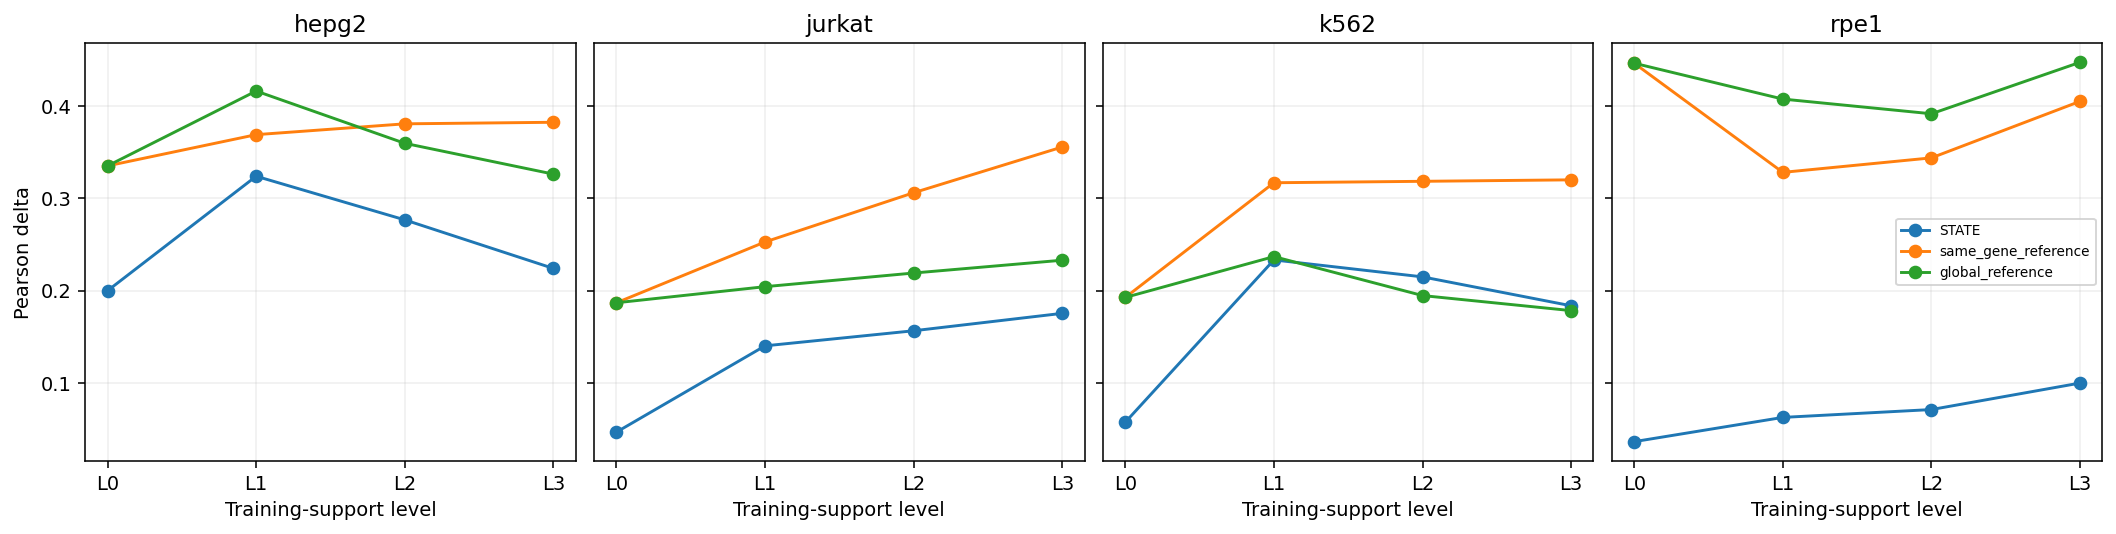

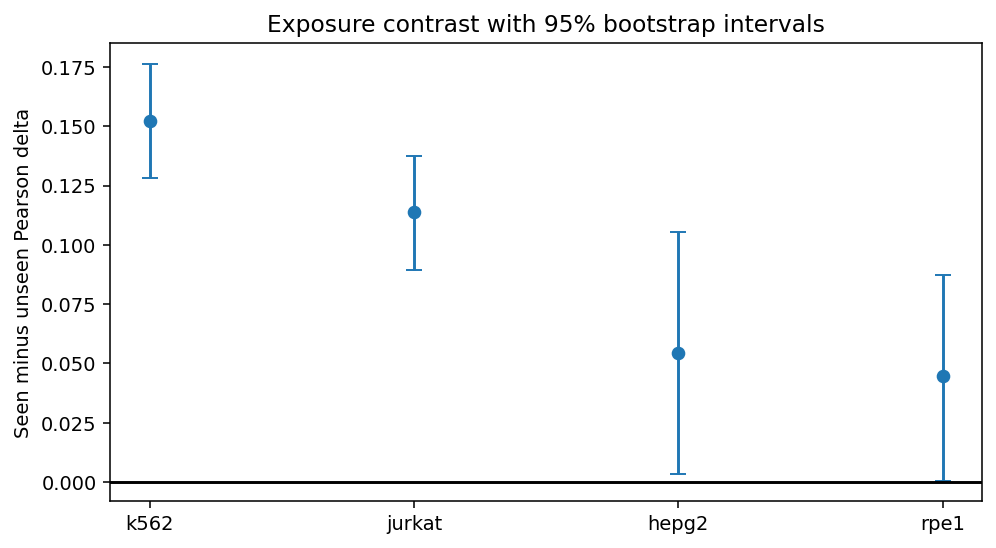

In [13]:
units=pd.read_csv(WORK/'results/per_unit_scores_all_contexts.csv');summary=pd.read_csv(WORK/'results/confirmation_summary.csv')
units['level']=pd.cut(units.support,[-1,0,100,250,10**9],labels=['L0','L1','L2','L3'])
curve=units.groupby(['context','level'],observed=True).agg(n=('pert','size'),STATE=('state_pearson_delta','mean'),same_gene_reference=('r1_pearson_delta','mean'),global_reference=('r2_pearson_delta','mean')).reset_index()
display(curve);display(summary)
fig,axes=plt.subplots(1,4,figsize=(15,3.7),layout='constrained',sharey=True)
for ax,(context,g) in zip(axes,curve.groupby('context',sort=False)):
    for name in ['STATE','same_gene_reference','global_reference']:ax.plot(g.level.astype(str),g[name],'o-',label=name)
    ax.set(title=context,xlabel='Training-support level');ax.grid(alpha=.2)
axes[0].set_ylabel('Pearson delta');axes[-1].legend(fontsize=7);display_figure(fig);plt.close(fig)
fig,ax=plt.subplots(figsize=(7,3.8),layout='constrained')
ax.errorbar(summary.context,summary.state_drop,yerr=np.maximum(0,np.vstack([summary.state_drop-summary.boot_lo,summary.boot_hi-summary.state_drop])),fmt='o',capsize=4);ax.axhline(0,color='black');ax.set(ylabel='Seen minus unseen Pearson delta',title='Exposure contrast with 95% bootstrap intervals');display_figure(fig);plt.close(fig)


,context,group,mean_norm,sd_norm,n
0,k562,unexposed,0.233215,0.005663,74
1,k562,support above 250,6.089521,1.324144,371
2,jurkat,unexposed,0.231638,0.006427,71
3,jurkat,support above 250,5.618502,1.480350,500
4,hepg2,unexposed,0.232328,0.005150,62
5,hepg2,support above 250,5.330475,1.476889,666
6,rpe1,unexposed,0.232230,0.005510,66
7,rpe1,support above 250,6.037446,1.240280,558


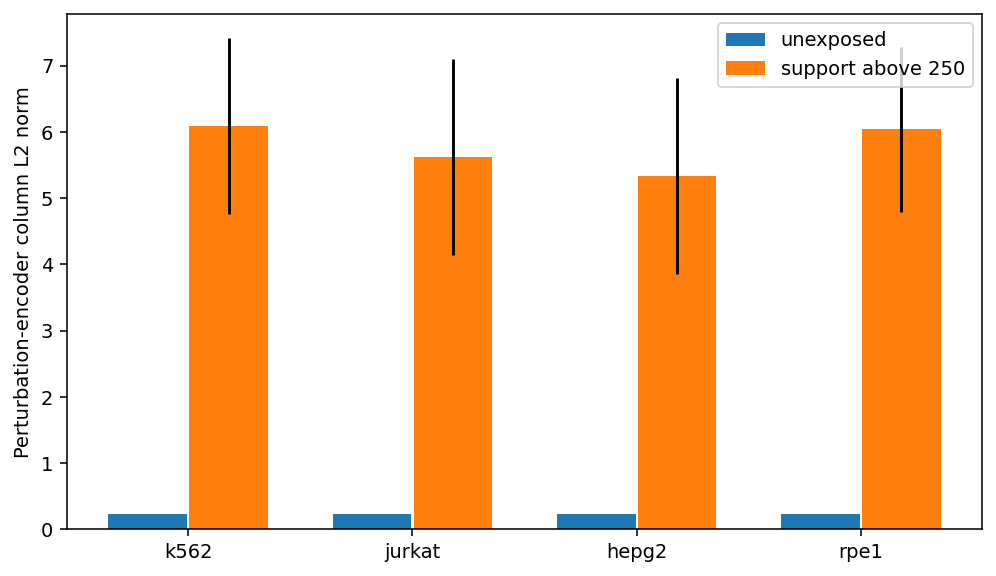

In [14]:
mechanism=[]
for ctx in ['k562','jurkat','hepg2','rpe1']:
    ck=torch.load(RAW/f'models/zeroshot_{ctx}/checkpoints/best.ckpt',map_location='cpu',weights_only=False)
    W=ck['state_dict']['pert_encoder.0.weight'];norms=W.norm(dim=0)
    maps=torch.load(RAW/f'models/zeroshot_{ctx}/pert_onehot_map.pt',map_location='cpu',weights_only=False)
    index={p:int(v.argmax()) for p,v in maps.items()}
    g=axis_table[axis_table.context.eq(ctx)]
    for label,q in [('unexposed',g[g.support.eq(0)]),('support above 250',g[g.support>250])]:
        values=norms[[index[p] for p in q.pert if p in index]].numpy();mechanism.append({'context':ctx,'group':label,'mean_norm':values.mean(),'sd_norm':values.std(ddof=1),'n':len(values)})
mechanism=pd.DataFrame(mechanism);display(mechanism)
fig,ax=plt.subplots(figsize=(7,4),layout='constrained')
for label,shift in [('unexposed',-.18),('support above 250',.18)]:
    q=mechanism[mechanism.group.eq(label)];ax.bar(np.arange(len(q))+shift,q.mean_norm,width=.35,yerr=q.sd_norm,label=label)
ax.set_xticks(np.arange(4),['k562','jurkat','hepg2','rpe1']);ax.set(ylabel='Perturbation-encoder column L2 norm');ax.legend();display_figure(fig);plt.close(fig)


## 6. What the agent decided, and why

In [15]:
display(summary[['context','state_drop','r1_drop','state_n0','r2_n0','state_below_r2_at_n0']])
print('Decision: compare STATE with the same-example references. Exposure-related loss can be shared by the gene-specific reference; performance below the global mean and small unexposed embedding norms supply separate mechanism diagnostics.')

,context,state_drop,r1_drop,state_n0,r2_n0,state_below_r2_at_n0
0,k562,0.152423,0.126103,0.057157,0.192534,1.0
1,jurkat,0.113748,0.127671,0.046404,0.186729,1.0
2,hepg2,0.054539,0.045209,0.199818,0.335246,1.0
3,rpe1,0.044790,-0.081051,0.036053,0.446607,1.0


Decision: compare STATE with the same-example references. Exposure-related loss can be shared by the gene-specific reference; performance below the global mean and small unexposed embedding norms supply separate mechanism diagnostics.


In [16]:
(WORK/'execution_record.json').write_text(json.dumps({'completed':True,'host':platform.node(),'elapsed_seconds':time.time()-START,'sources':SOURCES,'inference':inference_status,'score_rows':len(units),'all_axis_and_metric_calculations_fresh':True,'external_custom_code_used':False},indent=2))

10128